## 1. Библиотеки и устройство

In [1]:
import html
import random
import re
from collections import Counter
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid")
device = torch.device("cpu")
print("pytorch:", torch.__version__)
print("устройство:", torch.cuda.get_device_name() if device.type == "cuda" else "cpu")
if device.type == "cuda":
    print("свободно гб:", round(torch.cuda.mem_get_info()[0] / 1024**3, 2))


pytorch: 2.7.1+cu126
устройство: cpu


## 2. Чтение AG News и объединение текстов

In [2]:
raw_train = pd.read_csv("data/train.csv")
raw_test = pd.read_csv("data/test.csv")
class_names = ["World", "Sports", "Business", "Sci/Tech"]

display(raw_train.head(3))
display(pd.DataFrame({"train_missing": raw_train.isna().sum(), "test_missing": raw_test.isna().sum()}))
print("train:", raw_train.shape, "test:", raw_test.shape)

def prepare_texts(frame):
    result = frame.copy()
    result["text"] = (result["Title"].fillna("") + " " + result["Description"].fillna("")).map(html.unescape).str.strip().str.lower()
    result["label"] = result["Class Index"] - 1
    return result

train_source = prepare_texts(raw_train)
test_df = prepare_texts(raw_test)
display(train_source["label"].value_counts().sort_index().rename_axis("label").to_frame("documents"))
print("пустых текстов:", train_source.text.eq("").sum())


,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...


,train_missing,test_missing
Class Index,0,0
Title,0,0
Description,0,0


train: (120000, 3) test: (7600, 3)


,documents
label,
0,30000
1,30000
2,30000
3,30000


пустых текстов: 0


## 3. Очистка повторов и разделение выборок

строк с противоречивыми метками: 28
повторных строк: 86 совпадений с test: 7


,train,validation,test
World,26992,2999,1900
Sports,26991,2999,1900
Business,26972,2997,1900
Sci/Tech,26936,2993,1900


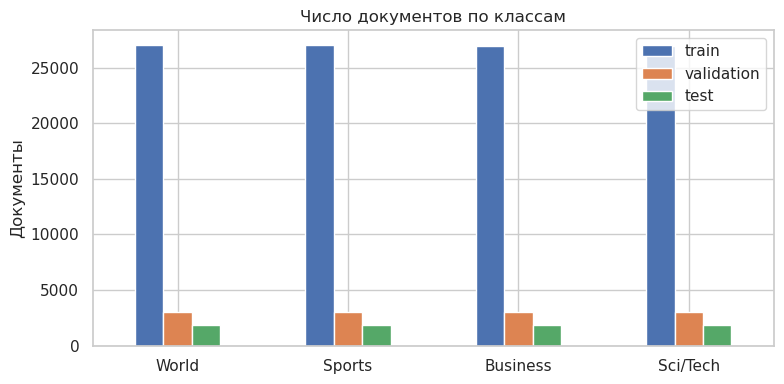

пересечение train / validation: 0
пересечение train / test: 0


In [3]:
conflicts = train_source.groupby("text").label.nunique()
conflict_texts = conflicts[conflicts > 1].index
clean = train_source[~train_source.text.isin(conflict_texts)].copy()
removed_conflicts = len(train_source) - len(clean)
removed_duplicates = clean.text.duplicated().sum()
clean = clean.drop_duplicates("text")
overlap = clean.text.isin(test_df.text)
removed_overlap = overlap.sum()
clean = clean[~overlap]
train_df, valid_df = train_test_split(clean, test_size=.1, stratify=clean.label, random_state=SEED)
train_df, valid_df = train_df.reset_index(drop=True), valid_df.reset_index(drop=True)

print("строк с противоречивыми метками:", removed_conflicts)
print("повторных строк:", removed_duplicates, "совпадений с test:", removed_overlap)
distribution = pd.DataFrame({name: frame.label.value_counts().sort_index()
                            for name, frame in [("train", train_df), ("validation", valid_df), ("test", test_df)]})
distribution.index = class_names
display(distribution)
distribution.plot.bar(figsize=(8, 4), rot=0, title="Число документов по классам")
plt.ylabel("Документы")
plt.tight_layout()
plt.show()
print("пересечение train / validation:", len(set(train_df.text) & set(valid_df.text)))
print("пересечение train / test:", len(set(train_df.text) & set(test_df.text)))


## 4. Токенизация и длины текстов

пример токенов: ['smith', 'steps', 'closer', 'to', 'scotland', "manager's", 'job', 'afp', 'afp', 'scottish', 'football', 'association', 'sfa', 'officials', 'confirmed', 'they', 'interviewed', 'walter', 'smith', 'for', 'the', 'vacant', 'national', 'managerial', 'job']


,tokens
count,107891.000000
mean,39.327785
std,11.006882
min,5.000000
50%,39.000000
90%,50.000000
95%,57.000000
99%,75.000000
max,177.000000


,max_length,document_coverage
0,64,0.974243
1,96,0.997386
2,128,0.999175


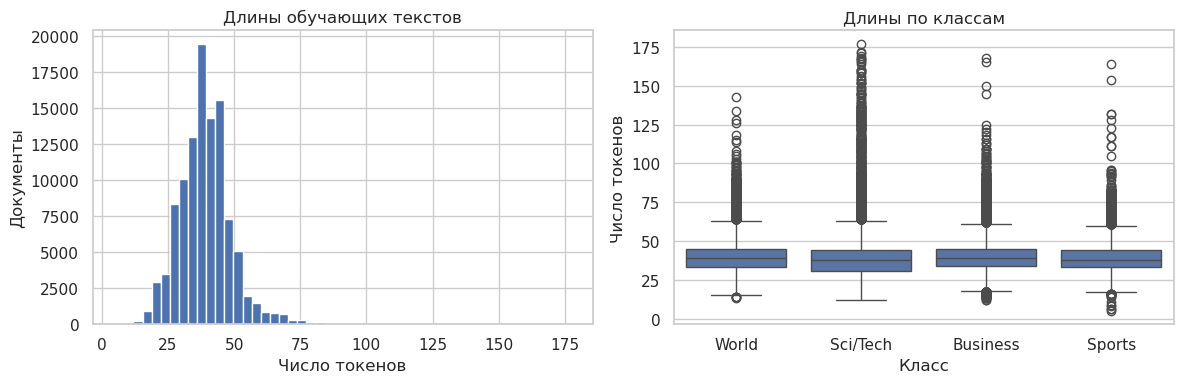

In [4]:
pattern = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+")

def tokenize(text):
    return pattern.findall(text)

train_tokens = [tokenize(text) for text in train_df.text]
valid_tokens = [tokenize(text) for text in valid_df.text]
lengths = np.array([len(tokens) for tokens in train_tokens])
print("пример токенов:", train_tokens[0][:25])
display(pd.Series(lengths).describe(percentiles=[.5, .9, .95, .99]).to_frame("tokens"))
length_coverage = pd.DataFrame({"max_length": [64, 96, 128],
                               "document_coverage": [(lengths <= limit).mean() for limit in [64, 96, 128]]})
display(length_coverage)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lengths, bins=50)
axes[0].set(xlabel="Число токенов", ylabel="Документы", title="Длины обучающих текстов")
sns.boxplot(x=train_df.label.map(dict(enumerate(class_names))), y=lengths, ax=axes[1])
axes[1].set(xlabel="Класс", ylabel="Число токенов", title="Длины по классам")
plt.tight_layout()
plt.show()


## 5. Словарь и кодирование текстов

In [5]:
word_counts = Counter(word for tokens in train_tokens for word in tokens)
total_tokens = sum(word_counts.values())
vocab_coverage = pd.DataFrame({"vocab_words": [10000, 20000, 30000],
                              "token_coverage": [sum(count for _, count in word_counts.most_common(size)) / total_tokens
                                                 for size in [10000, 20000, 30000]]})
display(vocab_coverage)
MAX_LENGTH = int(length_coverage.loc[length_coverage.document_coverage >= .99, "max_length"].iloc[0])
VOCAB_WORDS = int(vocab_coverage.loc[vocab_coverage.token_coverage >= .985, "vocab_words"].iloc[0])
word2idx = {"<PAD>": 0, "<UNK>": 1}
word2idx.update({word: i for i, (word, _) in enumerate(word_counts.most_common(VOCAB_WORDS), start=2)})

def encode(tokens):
    return torch.tensor([word2idx.get(word, 1) for word in tokens[:MAX_LENGTH]] or [1], dtype=torch.long)

train_data = [(encode(tokens), int(label)) for tokens, label in zip(train_tokens, train_df.label)]
valid_data = [(encode(tokens), int(label)) for tokens, label in zip(valid_tokens, valid_df.label)]
valid_oov = sum(word not in word2idx for tokens in valid_tokens for word in tokens) / sum(map(len, valid_tokens))
print("максимальная длина:", MAX_LENGTH, "размер словаря с pad/unk:", len(word2idx))
print("неизвестных токенов validation:", f"{valid_oov:.2%}")
print("индексы:", train_data[0][0][:25].tolist())


,vocab_words,token_coverage
0,10000,0.937170
1,20000,0.975000
2,30000,0.987974


максимальная длина: 96 размер словаря с pad/unk: 30002
неизвестных токенов validation: 1.59%
индексы: [1902, 1842, 1081, 3, 2323, 24486, 481, 105, 105, 3867, 372, 819, 16998, 154, 1103, 68, 9277, 6813, 1902, 9, 2, 8849, 187, 8218, 481]


## 6. Батчи и DataLoader

In [6]:
BATCH_SIZE = 128

def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    texts = pad_sequence(sequences, batch_first=True, padding_value=0)
    return texts, lengths, torch.tensor(labels, dtype=torch.long)

def make_loaders(batch_size=BATCH_SIZE):
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collate_batch,
                              generator=generator, num_workers=0, pin_memory=device.type == "cuda")
    valid_loader = DataLoader(valid_data, batch_size=batch_size, shuffle=False, collate_fn=collate_batch,
                              num_workers=0, pin_memory=device.type == "cuda")
    return train_loader, valid_loader

train_loader, valid_loader = make_loaders()
texts, lengths_batch, labels = next(iter(train_loader))
print("формы:", texts.shape, lengths_batch.shape, labels.shape)
print("длины:", lengths_batch[:10].tolist())
print("метки:", labels[:10].tolist())
print("токенов padding в батче:", int((texts == 0).sum()))


формы: torch.Size([128, 89]) torch.Size([128]) torch.Size([128])
длины: [39, 17, 39, 47, 45, 22, 44, 34, 39, 45]
метки: [2, 3, 0, 2, 0, 2, 2, 2, 1, 1]
токенов padding в батче: 6488


## 7. SimpleRNN, LSTM, GRU и BiLSTM

In [7]:
class NewsClassifier(nn.Module):
    def __init__(self, architecture, hidden_size=128, dropout=.3):
        super().__init__()
        self.bidirectional = architecture == "BiLSTM"
        recurrent_class = {"SimpleRNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU, "BiLSTM": nn.LSTM}[architecture]
        self.embedding = nn.Embedding(len(word2idx), 128, padding_idx=0)
        self.recurrent = recurrent_class(128, hidden_size, batch_first=True, bidirectional=self.bidirectional)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * (2 if self.bidirectional else 1), 4)

    def forward(self, texts, lengths):
        embedded = self.embedding(texts)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        hidden = state[0] if isinstance(state, tuple) else state
        final = torch.cat([hidden[-2], hidden[-1]], dim=1) if self.bidirectional else hidden[-1]
        return self.classifier(self.dropout(final))

parameter_rows = []
for architecture in ["SimpleRNN", "LSTM", "GRU", "BiLSTM"]:
    model = NewsClassifier(architecture)
    parameter_rows.append({"architecture": architecture,
                           "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                           "recurrent_parameters": sum(p.numel() for p in model.recurrent.parameters())})
display(pd.DataFrame(parameter_rows))
del model


,architecture,parameters,recurrent_parameters
0,SimpleRNN,3873796,33024
1,LSTM,3972868,132096
2,GRU,3939844,99072
3,BiLSTM,4105476,264192


## 8. Проверка моделей на одном батче

In [8]:
checks = []
for architecture in ["SimpleRNN", "LSTM", "GRU", "BiLSTM"]:
    set_seed()
    model = NewsClassifier(architecture).to(device)
    x, y = texts.to(device), labels.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(x, lengths_batch)
        padded_logits = model(torch.nn.functional.pad(x, (0, 7)), lengths_batch)
    assert logits.shape == (BATCH_SIZE, 4)
    assert torch.allclose(logits, padded_logits, atol=1e-6)
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=.001)
    loss = nn.CrossEntropyLoss()(model(x, lengths_batch), y)
    loss.backward()
    assert torch.isfinite(loss) and all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    optimizer.step()
    checks.append({"architecture": architecture, "batch_size": BATCH_SIZE, "loss": loss.item(),
                   "padding_difference": (logits - padded_logits).abs().max().item()})
    del model, optimizer, loss, logits, padded_logits, x, y
    if device.type == "cuda":
        torch.cuda.empty_cache()
display(pd.DataFrame(checks))


,architecture,batch_size,loss,padding_difference
0,SimpleRNN,128,1.507874,0.0
1,LSTM,128,1.381071,0.0
2,GRU,128,1.405015,0.0
3,BiLSTM,128,1.393200,0.0


## 9. Обучение и оценка одной эпохи

In [9]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for texts, lengths, labels in loader:
            texts = texts.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(texts, lengths)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return loss_sum / total, correct / total




## 10. Сохранение лучшей эпохи и сравнение экспериментов

In [10]:
def train_experiment(name, architecture, hidden_size=128, dropout=.3, epochs=8):
    set_seed()
    train_loader, valid_loader = make_loaders(BATCH_SIZE)
    model = NewsClassifier(architecture, hidden_size, dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=.001)
    history, best_accuracy, best_loss, stale = [], -1.0, float("inf"), 0
    if device.type == "cuda":
        torch.cuda.synchronize()
    started = perf_counter()
    for epoch in range(1, epochs + 1):
        epoch_started = perf_counter()
        train_loss, train_accuracy = run_epoch(model, train_loader, optimizer)
        if device.type == "cuda":
            torch.cuda.synchronize()
        train_seconds = perf_counter() - epoch_started
        valid_loss, valid_accuracy = run_epoch(model, valid_loader)
        history.append(dict(epoch=epoch, train_loss=train_loss, valid_loss=valid_loss,
                            train_accuracy=train_accuracy, valid_accuracy=valid_accuracy, train_seconds=train_seconds))
        print(f"{epoch:2d}/{epochs} | loss {train_loss:.4f} / {valid_loss:.4f} | accuracy {train_accuracy:.4f} / {valid_accuracy:.4f} | train {train_seconds:.1f} с", flush=True)
        if valid_accuracy > best_accuracy or (valid_accuracy == best_accuracy and valid_loss < best_loss):
            best_accuracy, best_loss, best_epoch, stale = valid_accuracy, valid_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        if stale >= 2:
            break
    model.load_state_dict(best_state)
    model.cpu()
    elapsed = perf_counter() - started
    del optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    result = dict(name=name, architecture=architecture, model=model, history=pd.DataFrame(history),
                best_epoch=best_epoch, valid_accuracy=best_accuracy, valid_loss=best_loss,
                fit_seconds=elapsed, device=device.type, hidden_size=hidden_size, dropout=dropout, epoch_limit=epochs)
    from pathlib import Path
    Path("models").mkdir(exist_ok=True)
    torch.save(dict(state_dict=model.state_dict(), word2idx=word2idx, max_length=MAX_LENGTH,
                    architecture=architecture, hidden_size=hidden_size, dropout=dropout,
                    history=history, best_epoch=best_epoch), f"models/{name}.pt")
    return result

def plot_learning(result):
    history = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        for split in ["train", "valid"]:
            ax.plot(history.epoch, history[f"{split}_{metric}"], marker="o", label=split)
        ax.axvline(result["best_epoch"], color="grey", linestyle="--")
        ax.set(xlabel="Эпоха", ylabel=metric, title=result["name"])
        ax.legend()
    plt.tight_layout()
    plt.show()

def compare_experiments(results):
    return pd.DataFrame([dict(model=r["name"], device=r.get("device", "cpu"), valid_accuracy=r["valid_accuracy"], valid_loss=r["valid_loss"],
                              best_epoch=r["best_epoch"], epochs=len(r["history"]),
                              parameters=sum(p.numel() for p in r["model"].parameters()),
                              recurrent_parameters=sum(p.numel() for p in r["model"].recurrent.parameters()),
                              seconds_per_epoch=r["history"].train_seconds.mean(), total_seconds=r["fit_seconds"])
                         for r in results])


## 11. Базовая SimpleRNN

 1/8 | loss 0.8460 / 0.5573 | accuracy 0.6470 / 0.8127 | train 57.1 с


 2/8 | loss 0.5078 / 0.4850 | accuracy 0.8342 / 0.8435 | train 55.5 с


 3/8 | loss 0.4142 / 0.4651 | accuracy 0.8729 / 0.8462 | train 55.7 с


 4/8 | loss 0.3686 / 0.3958 | accuracy 0.8896 / 0.8790 | train 47.8 с


 5/8 | loss 0.3262 / 0.4115 | accuracy 0.9035 / 0.8780 | train 55.6 с


 6/8 | loss 0.3000 / 0.3921 | accuracy 0.9123 / 0.8854 | train 56.2 с


 7/8 | loss 0.2709 / 0.3969 | accuracy 0.9213 / 0.8841 | train 55.7 с


 8/8 | loss 0.2475 / 0.3834 | accuracy 0.9285 / 0.8917 | train 55.5 с


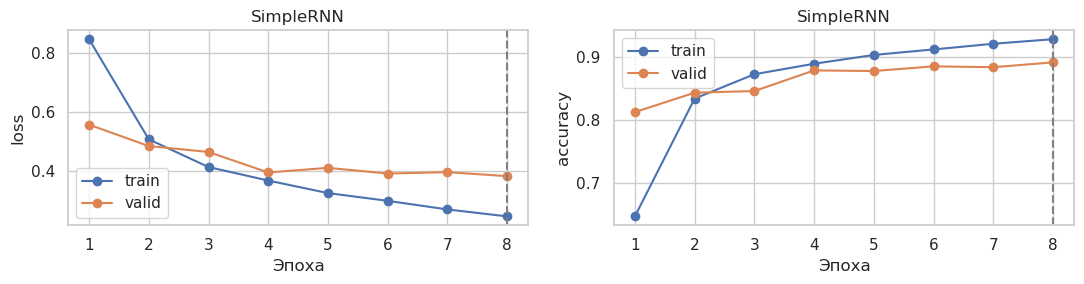

,model,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,SimpleRNN,0.891725,0.383421,8,8,3873796,33024,54.891455,446.399467


In [11]:
rnn_result = train_experiment("SimpleRNN", "SimpleRNN")
plot_learning(rnn_result)
display(compare_experiments([rnn_result]))


## 12. Обучение LSTM

 1/8 | loss 0.5848 / 0.3770 | accuracy 0.7784 / 0.8771 | train 229.0 с


 2/8 | loss 0.3001 / 0.3107 | accuracy 0.9032 / 0.9001 | train 225.6 с


 3/8 | loss 0.2304 / 0.2885 | accuracy 0.9269 / 0.9076 | train 224.4 с


 4/8 | loss 0.1849 / 0.2861 | accuracy 0.9415 / 0.9108 | train 225.5 с


 5/8 | loss 0.1498 / 0.3002 | accuracy 0.9530 / 0.9101 | train 226.0 с


 6/8 | loss 0.1211 / 0.3087 | accuracy 0.9620 / 0.9113 | train 225.3 с


 7/8 | loss 0.0969 / 0.3585 | accuracy 0.9692 / 0.9028 | train 219.0 с


 8/8 | loss 0.0780 / 0.3822 | accuracy 0.9751 / 0.9071 | train 218.3 с


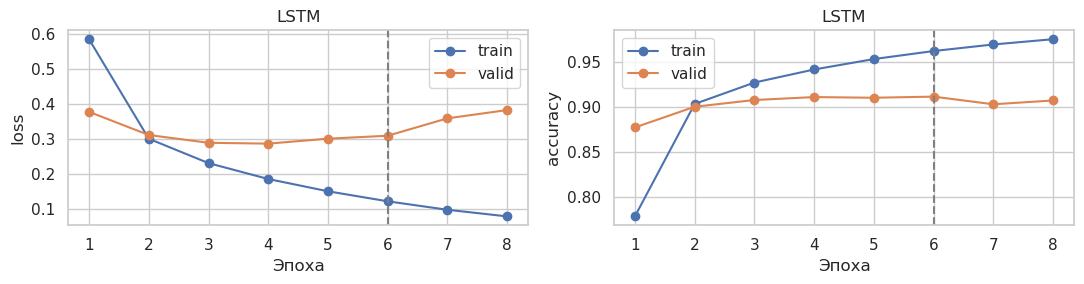

,model,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,SimpleRNN,0.891725,0.383421,8,8,3873796,33024,54.891455,446.399467
1,LSTM,0.911328,0.308726,6,8,3972868,132096,224.141114,1814.045095


In [12]:
lstm_result = train_experiment("LSTM", "LSTM")
plot_learning(lstm_result)
display(compare_experiments([rnn_result, lstm_result]))


## 13. Обучение GRU

 1/8 | loss 0.5534 / 0.3293 | accuracy 0.7879 / 0.8895 | train 152.4 с


 2/8 | loss 0.2748 / 0.2892 | accuracy 0.9102 / 0.9022 | train 155.6 с


 3/8 | loss 0.2087 / 0.2697 | accuracy 0.9322 / 0.9093 | train 150.4 с


 4/8 | loss 0.1624 / 0.2805 | accuracy 0.9476 / 0.9113 | train 150.5 с


 5/8 | loss 0.1239 / 0.2991 | accuracy 0.9600 / 0.9080 | train 150.3 с


 6/8 | loss 0.0940 / 0.3235 | accuracy 0.9685 / 0.9067 | train 150.5 с


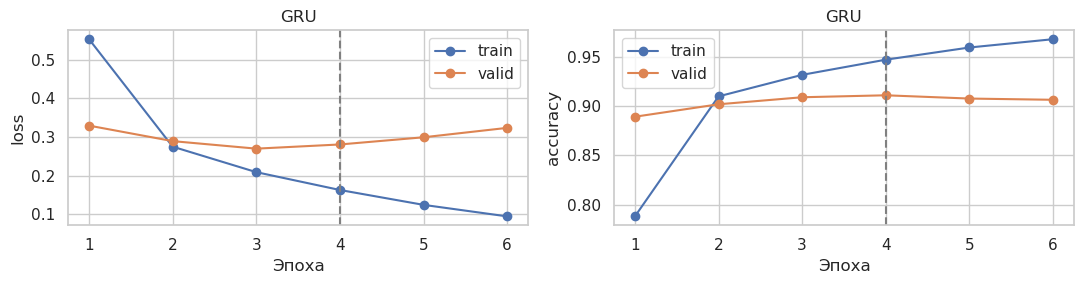

,model,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,SimpleRNN,0.891725,0.383421,8,8,3873796,33024,54.891455,446.399467
1,LSTM,0.911328,0.308726,6,8,3972868,132096,224.141114,1814.045095
2,GRU,0.911328,0.280516,4,6,3939844,99072,151.625749,921.358881


In [13]:
gru_result = train_experiment("GRU", "GRU")
plot_learning(gru_result)
display(compare_experiments([rnn_result, lstm_result, gru_result]))


## 14. Устройство для следующих экспериментов

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.3)
print("устройство:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name())


устройство: cuda
NVIDIA GeForce GTX 1650


## 15. Обучение двунаправленной LSTM

 1/8 | loss 0.5087 / 0.3127 | accuracy 0.8111 / 0.8936 | train 26.5 с


 2/8 | loss 0.2589 / 0.2810 | accuracy 0.9131 / 0.9046 | train 23.9 с


 3/8 | loss 0.1935 / 0.2691 | accuracy 0.9353 / 0.9097 | train 24.8 с


 4/8 | loss 0.1471 / 0.2737 | accuracy 0.9506 / 0.9098 | train 24.6 с


 5/8 | loss 0.1079 / 0.3088 | accuracy 0.9634 / 0.9094 | train 24.1 с


 6/8 | loss 0.0800 / 0.3363 | accuracy 0.9731 / 0.9067 | train 23.3 с


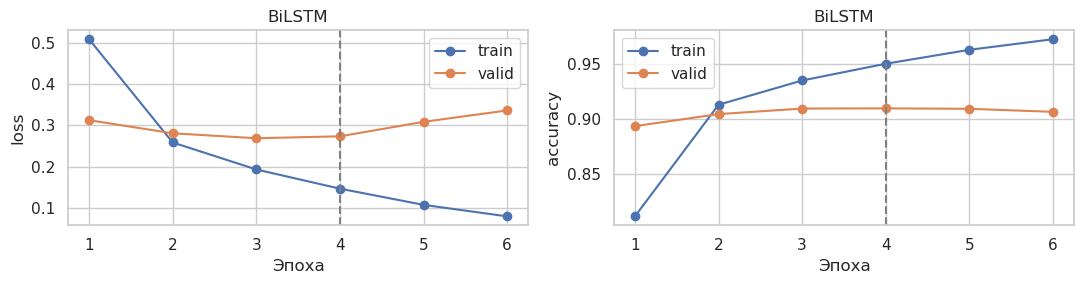

,model,device,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,SimpleRNN,cpu,0.891725,0.383421,8,8,3873796,33024,54.891455,446.399467
1,LSTM,cpu,0.911328,0.308726,6,8,3972868,132096,224.141114,1814.045095
2,GRU,cpu,0.911328,0.280516,4,6,3939844,99072,151.625749,921.358881
3,BiLSTM,cuda,0.909826,0.273716,4,6,4105476,264192,24.532230,152.661495


In [12]:
bilstm_result = train_experiment("BiLSTM", "BiLSTM")
plot_learning(bilstm_result)
baselines = [rnn_result, lstm_result, gru_result, bilstm_result]
display(compare_experiments(baselines))


## 16. Сравнение базовых моделей

In [13]:
baseline_table = compare_experiments(baselines)
best_baseline = min(baselines, key=lambda r: (-r["valid_accuracy"], r["valid_loss"]))
diagnostics = []
for result in baselines:
    row = result["history"].set_index("epoch").loc[result["best_epoch"]]
    diagnostics.append(dict(model=result["name"], best_epoch=result["best_epoch"],
                            train_accuracy=row.train_accuracy, valid_accuracy=row.valid_accuracy,
                            gap=row.train_accuracy - row.valid_accuracy))
display(pd.DataFrame(diagnostics))
print("лучшая базовая модель:", best_baseline["name"])


,model,best_epoch,train_accuracy,valid_accuracy,gap
0,SimpleRNN,8,0.928548,0.891725,0.036823
1,LSTM,6,0.961952,0.911328,0.050624
2,GRU,4,0.947623,0.911328,0.036295
3,BiLSTM,4,0.950645,0.909826,0.040818


лучшая базовая модель: GRU


## 17. Базовая GRU на текущем устройстве

 1/8 | loss 0.5518 / 0.3291 | accuracy 0.7890 / 0.8899 | train 14.9 с


 2/8 | loss 0.2749 / 0.2867 | accuracy 0.9095 / 0.9034 | train 14.6 с


 3/8 | loss 0.2094 / 0.2720 | accuracy 0.9319 / 0.9082 | train 14.6 с


 4/8 | loss 0.1612 / 0.2850 | accuracy 0.9474 / 0.9082 | train 14.6 с


 5/8 | loss 0.1239 / 0.2894 | accuracy 0.9599 / 0.9087 | train 13.6 с


 6/8 | loss 0.0937 / 0.3165 | accuracy 0.9691 / 0.9086 | train 12.8 с


 7/8 | loss 0.0679 / 0.3877 | accuracy 0.9776 / 0.9027 | train 12.7 с


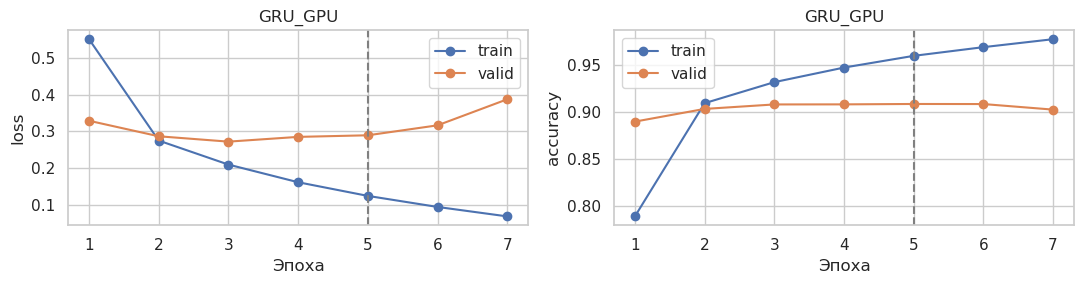

,model,device,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,GRU,cpu,0.911328,0.280516,4,6,3939844,99072,151.625749,921.358881
1,GRU_GPU,cuda,0.908659,0.289380,5,7,3939844,99072,13.978085,101.225210


In [14]:
gru_gpu_result = train_experiment("GRU_GPU", "GRU")
plot_learning(gru_gpu_result)
display(compare_experiments([gru_result, gru_gpu_result]))


## 18. GRU с усиленным dropout

 1/8 | loss 0.5754 / 0.3307 | accuracy 0.7793 / 0.8903 | train 13.0 с


 2/8 | loss 0.2842 / 0.2899 | accuracy 0.9078 / 0.9024 | train 12.6 с


 3/8 | loss 0.2201 / 0.2747 | accuracy 0.9288 / 0.9082 | train 13.0 с


 4/8 | loss 0.1736 / 0.2826 | accuracy 0.9443 / 0.9113 | train 12.7 с


 5/8 | loss 0.1380 / 0.2947 | accuracy 0.9561 / 0.9112 | train 12.6 с


 6/8 | loss 0.1090 / 0.3131 | accuracy 0.9647 / 0.9064 | train 12.8 с


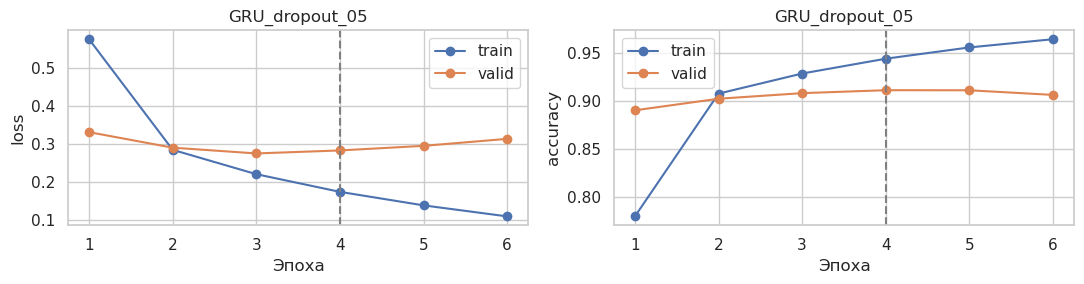

,model,device,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
0,GRU_GPU,cuda,0.908659,0.28938,5,7,3939844,99072,13.978085,101.225210
1,GRU_dropout_05,cuda,0.911328,0.28260,4,6,3939844,99072,12.783544,79.327713


In [15]:
gru_dropout_result = train_experiment("GRU_dropout_05", "GRU", dropout=.5)
plot_learning(gru_dropout_result)
display(compare_experiments([gru_gpu_result, gru_dropout_result]))


## 19. Скорость архитектур на одном устройстве

,model,device,median_step_ms,mean_step_ms
0,SimpleRNN,cuda,12.013380,12.354063
1,LSTM,cuda,14.340089,14.445290
2,GRU,cuda,14.882488,14.782565
3,BiLSTM,cuda,25.047239,28.874298


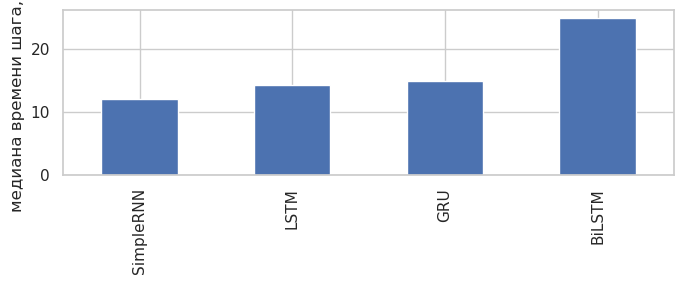

In [16]:
benchmark_rows = []
benchmark_texts, benchmark_lengths, benchmark_labels = next(iter(make_loaders()[0]))
benchmark_texts = benchmark_texts.to(device)
benchmark_labels = benchmark_labels.to(device)
for architecture in ["SimpleRNN", "LSTM", "GRU", "BiLSTM"]:
    set_seed()
    probe = NewsClassifier(architecture).to(device)
    optimizer = torch.optim.Adam(probe.parameters(), lr=.001)
    step_times = []
    for step in range(35):
        if device.type == "cuda":
            torch.cuda.synchronize()
        started = perf_counter()
        optimizer.zero_grad(set_to_none=True)
        logits = probe(benchmark_texts, benchmark_lengths)
        loss = criterion(logits, benchmark_labels)
        loss.backward()
        nn.utils.clip_grad_norm_(probe.parameters(), 1.0)
        optimizer.step()
        if device.type == "cuda":
            torch.cuda.synchronize()
        if step >= 5:
            step_times.append((perf_counter() - started) * 1000)
    benchmark_rows.append(dict(model=architecture, device=device.type,
                               median_step_ms=np.median(step_times), mean_step_ms=np.mean(step_times)))
    del probe, optimizer, logits, loss
    if device.type == "cuda":
        torch.cuda.empty_cache()
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark)
benchmark.plot.bar(x="model", y="median_step_ms", legend=False, figsize=(7, 3))
plt.ylabel("медиана времени шага, мс")
plt.xlabel("")
plt.tight_layout()
plt.show()
del benchmark_texts, benchmark_labels, benchmark_lengths


## 20. Общие кривые и выбор модели

,model,device,valid_accuracy,valid_loss,best_epoch,epochs,parameters,recurrent_parameters,seconds_per_epoch,total_seconds
2,GRU,cpu,0.911328,0.280516,4,6,3939844,99072,151.625749,921.358881
5,GRU_dropout_05,cuda,0.911328,0.282600,4,6,3939844,99072,12.783544,79.327713
1,LSTM,cpu,0.911328,0.308726,6,8,3972868,132096,224.141114,1814.045095
3,BiLSTM,cuda,0.909826,0.273716,4,6,4105476,264192,24.532230,152.661495
4,GRU_GPU,cuda,0.908659,0.289380,5,7,3939844,99072,13.978085,101.225210
0,SimpleRNN,cpu,0.891725,0.383421,8,8,3873796,33024,54.891455,446.399467


выбрана по validation: GRU


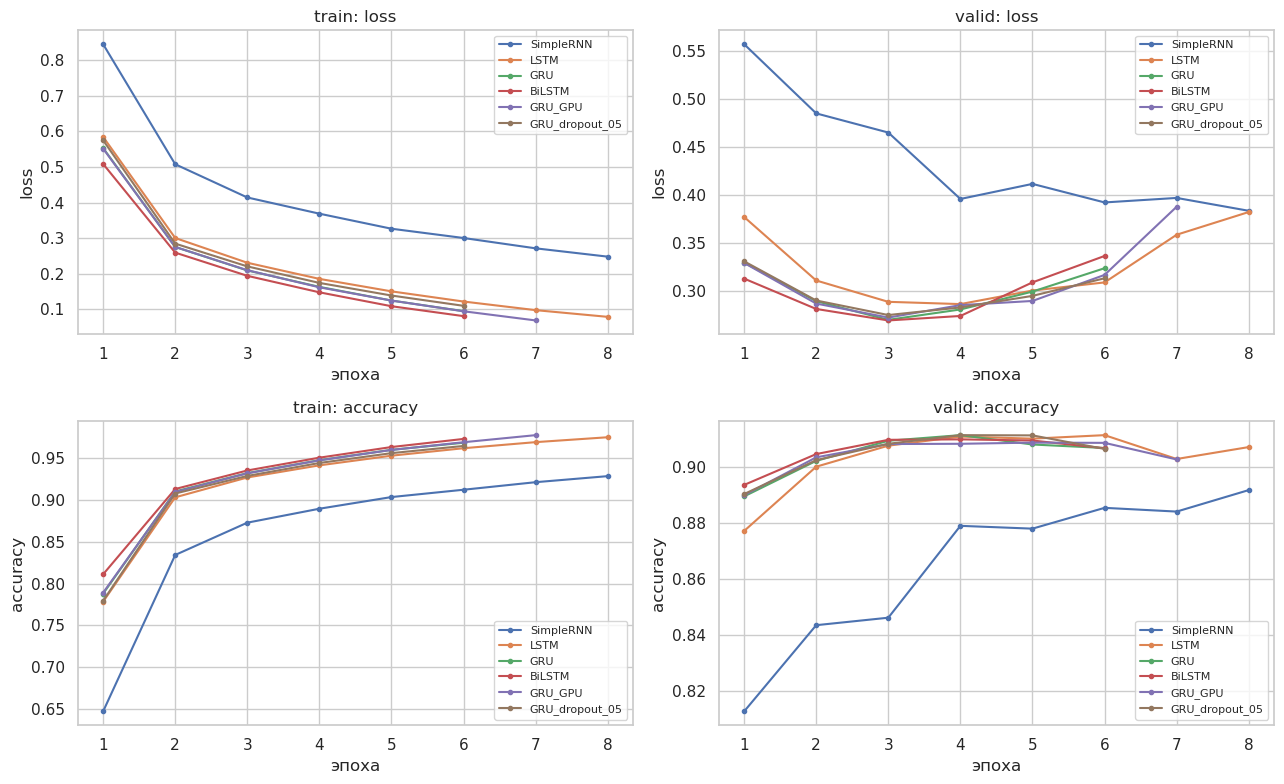

In [17]:
experiments = baselines + [gru_gpu_result, gru_dropout_result]
comparison = compare_experiments(experiments).sort_values(["valid_accuracy", "valid_loss"], ascending=[False, True])
best_result = min(experiments, key=lambda r: (-r["valid_accuracy"], r["valid_loss"]))
display(comparison)
print("выбрана по validation:", best_result["name"])
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for result in experiments:
    history = result["history"]
    for row, metric in enumerate(["loss", "accuracy"]):
        for col, split in enumerate(["train", "valid"]):
            axes[row, col].plot(history.epoch, history[f"{split}_{metric}"], marker=".", label=result["name"])
            axes[row, col].set(xlabel="эпоха", ylabel=metric, title=f"{split}: {metric}")
for ax in axes.flat:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 21. Итоговая оценка на тестовой выборке

In [18]:
test_tokens = test_df.text.map(tokenize).tolist()
test_data = [(encode(tokens), int(label)) for tokens, label in zip(test_tokens, test_df.label)]
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, num_workers=0)

def predict_dataset(model, loader):
    model = model.to(device)
    model.eval()
    probabilities, targets = [], []
    with torch.inference_mode():
        for texts, lengths, labels in loader:
            logits = model(texts.to(device), lengths)
            probabilities.append(logits.softmax(dim=1).cpu())
            targets.append(labels)
    model.cpu()
    return torch.cat(targets).numpy(), torch.cat(probabilities).numpy()

test_rows, predictions = [], {}
for result in experiments:
    y_true, probabilities = predict_dataset(result["model"], test_loader)
    y_pred = probabilities.argmax(axis=1)
    predictions[result["name"]] = (y_pred, probabilities)
    test_rows.append(dict(model=result["name"], accuracy=accuracy_score(y_true, y_pred),
                          macro_f1=f1_score(y_true, y_pred, average="macro")))
test_results = pd.DataFrame(test_rows)
display(test_results)
print("выбранная до тестирования модель:", best_result["name"])


,model,accuracy,macro_f1
0,SimpleRNN,0.883158,0.883309
1,LSTM,0.906974,0.906671
2,GRU,0.908026,0.907732
3,BiLSTM,0.906842,0.906602
4,GRU_GPU,0.902895,0.902895
5,GRU_dropout_05,0.909868,0.909640


выбранная до тестирования модель: GRU


## 22. Отчёт и матрица ошибок выбранной модели

              precision    recall  f1-score   support

       World     0.9129    0.9100    0.9114      1900
      Sports     0.9427    0.9705    0.9564      1900
    Business     0.8901    0.8611    0.8753      1900
    Sci/Tech     0.8849    0.8905    0.8877      1900

    accuracy                         0.9080      7600
   macro avg     0.9077    0.9080    0.9077      7600
weighted avg     0.9077    0.9080    0.9077      7600



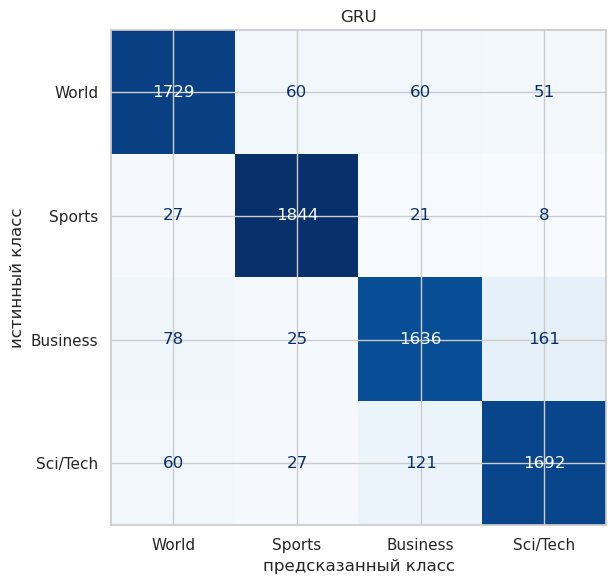

In [19]:
best_predictions, best_probabilities = predictions[best_result["name"]]
print(classification_report(y_true, best_predictions, target_names=class_names, digits=4))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, best_predictions, display_labels=class_names,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set(title=best_result["name"], xlabel="предсказанный класс", ylabel="истинный класс")
plt.tight_layout()
plt.show()


## 23. Примеры ошибочной классификации

In [20]:
errors = test_df.loc[y_true != best_predictions, ["Title", "Description", "text"]].copy()
errors["true_class"] = [class_names[i] for i in y_true[y_true != best_predictions]]
errors["predicted_class"] = [class_names[i] for i in best_predictions[y_true != best_predictions]]
errors["confidence"] = best_probabilities.max(axis=1)[y_true != best_predictions]
confident_errors = errors.nlargest(3, "confidence")
random_errors = errors.drop(confident_errors.index).sample(n=3, random_state=SEED)
examples = pd.concat([confident_errors.assign(selection="уверенные"), random_errors.assign(selection="случайные")])
for index, row in examples.iterrows():
    print(f"#{index} | {row.selection} | {row.true_class} → {row.predicted_class} | {row.confidence:.2%}")
    print(row.Title)
    print(row.Description)
    print()
print("всего ошибок:", len(errors), "из", len(test_df))


#1269 | уверенные | Sci/Tech → World | 99.93%
Philippines mourns dead in Russian school siege
The Philippines Saturday expressed quot;deepest sympathy quot; to the families of the dead in the Russian school siege on Friday, in which 322 people were killed when Russian troops stormed 

#355 | уверенные | World → Sports | 99.87%
Greek weightlifter awaits verdict
Greek weightlifter Leonidas Sampanis will find out on Sunday if he is to be stripped of his medal.

#4275 | уверенные | Business → World | 99.84%
Erdogan Believes European Council #39;s Decision Will Be A Milestone
PARIS - Turkish PM Recep Tayyip Erdogan expressed belief on Thursday that the decision that the European Council would make on December 17th (on whether and when to open negotiations with Turkey) would be a milestone for not only Turkey-(EU) relations 

#7305 | случайные | Sci/Tech → Business | 78.82%
Take Two Torts and Call Me in the Morning
The friction that sometimes strains the patient-doctor relationship when lawy